# From rates to steps: a mixed chamber

Can a perfectly consistent computer calculation predict a physically impossible amount?

Fall 2024.


## Predict
Starting empty, predict the first two1-minute Euler masses for input2 mg/min and removal constant0.25/min. Write the units before running.

In [1]:
from demo import simulate, exact, checks
import numpy as np
import matplotlib.pyplot as plt
t, mass, removed = simulate()
list(zip(t[:3], mass[:3]))

[(np.float64(0.0), np.float64(0.0)),
 (np.float64(1.0), np.float64(2.0)),
 (np.float64(2.0), np.float64(3.5))]

## Compare
At the same physical times, compare the explicit update with the continuous reference. Which assumption in the numerical step explains the gap?

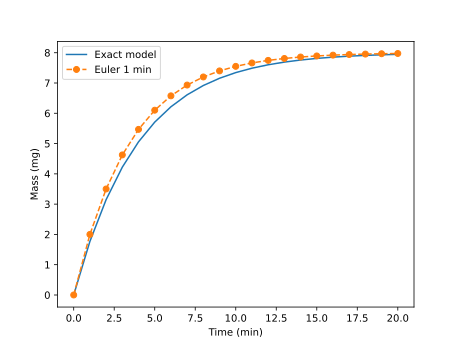

In [2]:
plt.plot(t, exact(t), label='Exact model')
plt.plot(t, mass, 'o--', label='Euler 1 min')
plt.xlabel('Time (min)'); plt.ylabel('Mass (mg)'); plt.legend(); 
from io import StringIO
from IPython.display import SVG, display
svg = StringIO()
plt.gcf().savefig(svg, format='svg')
display(SVG(data=svg.getvalue()))
plt.close()

## Modify one choice
Predict what a5-minute step will do. Then change only the step. Keep model parameters and final time fixed. Try9 minutes and explain any impossible values.

In [3]:
for h in [1.,5.,9.]:
    th,mh,_ = simulate(dt=h,end=27.)
    print('step',h,'minimum mass',mh.min(),'final mass',mh[-1])

step 1.0 minimum mass 0.0 final mass 7.996613554438257
step 5.0 minimum mass 0.0 final mass 8.00390625
step 9.0 minimum mass -4.5 final mass 23.625


## Verify and interpret
Read the checks below. Which tests concern conservation, which concern accuracy, and which only confirm detection of a bad numerical choice? Passing these tests does not validate the laboratory assumptions.

In [4]:
checks()

{'balance_max_mg': 0.0,
 'end4_errors_mg': [0.19416420292500547,
  0.09444248575719616,
  0.04659321532100602],
 'refinement_ratios': [2.0558989036373485, 2.026957897336135],
 'unstable_values_mg': [0.0, 18.0, -4.5, 23.625],
 'invalid_cases_rejected': 5}